## Machine Learning Project Portfolio: Capital Bike-Share Analysis


**This notebook compiles a sequence of machine learning tasks focused entirely on the Capital Bike-Share dataset (2011-2012).**  
**Project Progression:**  
**Regression Modeling:** The project begins with regression tasks to predict total hourly bicycle rental counts, ensuring no target data leakage by strictly excluding component columns like `casual` and `registered`.  
**Feature & Interaction Analysis:** Subsequent steps expand the regression models by evaluating how relationships between weather variables, wind speed, and rental counts differ across weekdays and weekends for different rider groups.  
**Classification Transition:** The final tasks transition from continuous regression to binary classification by predicting categorical outcomes.


**Data Loading & Preprocessing**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

plt.style.use("seaborn-v0_8-whitegrid")

df = pd.read_csv("hour.csv")
df['dteday'] = pd.to_datetime(df['dteday'])

df = df.drop(columns=['casual', 'registered'])

angle = 2 * np.pi * df["hr"] / 24
df["hour_sin"] = np.sin(angle)
df["hour_cos"] = np.cos(angle)

df["evening"] = df["hr"].isin([17, 18, 19, 20]).astype(int)
df["temp_x_evening"] = df["temp"] * df["evening"]

df = df.sort_values(by=["dteday", "hr"]).reset_index(drop=True)
df.head(3)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt,hour_sin,hour_cos,evening,temp_x_evening
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16,0.000000,1.000000,0,0.0
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40,0.258819,0.965926,0,0.0
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32,0.500000,0.866025,0,0.0


**Data Visualization**

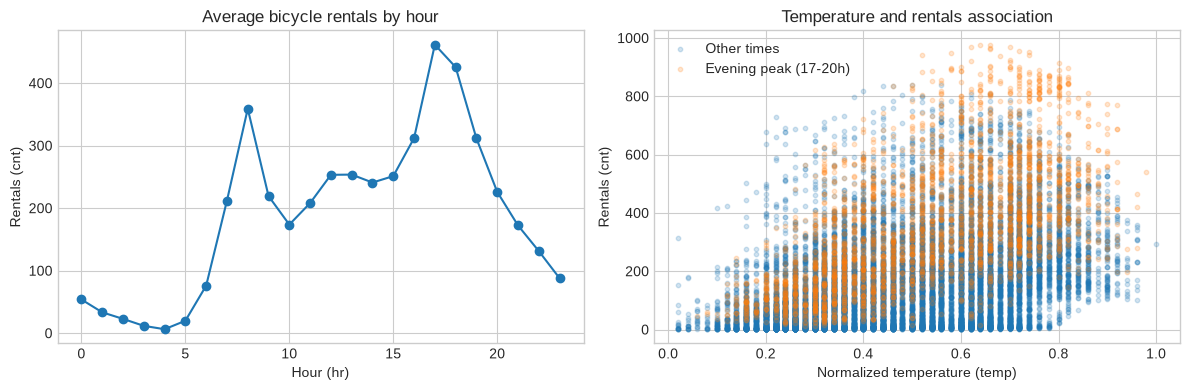

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.groupby("hr")["cnt"].mean().plot(marker="o", ax=axes[0])
axes[0].set_title("Average bicycle rentals by hour")
axes[0].set_xlabel("Hour (hr)")
axes[0].set_ylabel("Rentals (cnt)")

for is_evening, group in df.groupby("evening"):
    label = "Evening peak (17-20h)" if is_evening else "Other times"
    axes[1].scatter(group["temp"], group["cnt"], alpha=0.2, s=10, label=label)
    
axes[1].set_title("Temperature and rentals association")
axes[1].set_xlabel("Normalized temperature (temp)")
axes[1].set_ylabel("Rentals (cnt)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Insights**  
Bimodal Daily Demand: Hourly rentals peak sharply during morning (8:00) and evening (17:00–18:00) commuter hours.  
Temperature & Evening Effect: Higher normalized temperatures correlate with increased rental volumes, with evening peak hours (17–20h) consistently yielding higher demand across all temperature levels.

**Chronological Train/Test Split**

In [3]:
cutoff_idx = int(0.80 * len(df))
train = df.iloc[:cutoff_idx].copy()
test = df.iloc[cutoff_idx:].copy()

print(f"Training period: {train['dteday'].min().date()} to {train['dteday'].max().date()}")
print(f"Testing period: {test['dteday'].min().date()} to {test['dteday'].max().date()}")

Training period: 2011-01-01 to 2012-08-07
Testing period: 2012-08-07 to 2012-12-31


**Model Fitting & Evaluation**

In [4]:
def fit_and_eval(features):
    model = LinearRegression().fit(train[features], train["cnt"])
    preds = model.predict(test[features])
    rmse = np.sqrt(mean_squared_error(test["cnt"], preds))
    r2 = r2_score(test["cnt"], preds)
    return model, preds, {"R2": r2, "RMSE": rmse}

base_features = ["temp", "hour_sin", "hour_cos"]
inter_features = base_features + ["evening", "temp_x_evening"]

m_base, p_base, s_base = fit_and_eval(base_features)
m_inter, p_inter, s_inter = fit_and_eval(inter_features)

results = pd.DataFrame([s_base, s_inter], index=["Base model", "Model with interaction"])
display(results.round(3))

,R2,RMSE
Base model,0.298,184.779
Model with interaction,0.384,173.031


The model that includes interaction terms performs better than the base model, demonstrating a higher $R^2$ score (0.384 compared to 0.298) and a lower Root Mean Square Error (173.031 compared to 184.779). The interaction model performs better because it explicitly accounts for sudden evening commuter spikes and recognizes that temperature has a stronger impact on rental demand during those specific peak hours.

**Residual Diagnostics**

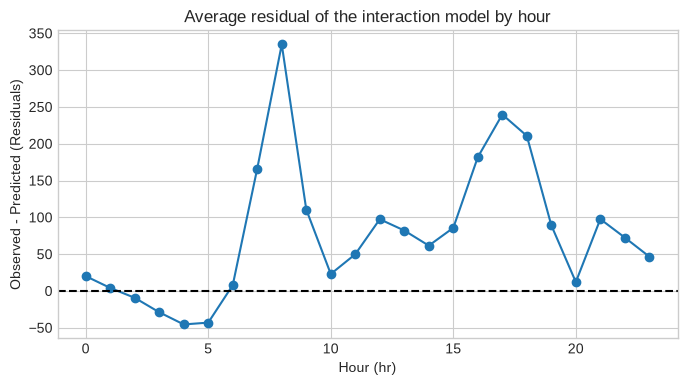

In [5]:
test["prediction"] = p_inter
test["residual"] = test["cnt"] - p_inter

hourly_diag = test.groupby("hr").agg(mean_residual=("residual", "mean"))

plt.figure(figsize=(8, 4))
hourly_diag["mean_residual"].plot(marker="o")
plt.axhline(0, color="black", linestyle="--")
plt.title("Average residual of the interaction model by hour")
plt.xlabel("Hour (hr)")
plt.ylabel("Observed - Predicted (Residuals)")
plt.show()

Despite this improvement, the residual plot reveals that the interaction model still systematically underpredicts rental demand during peak commuter hours, as shown by the large positive spikes in residuals around 8:00 and 17:00.

**Data Reloading & Preprocessing**

In [6]:
# Reloading the data because casual and registered columns were dropped 
df = pd.read_csv("hour.csv")
df['dteday'] = pd.to_datetime(df['dteday'])

df = df[df['holiday'] == 0].copy()
df['is_weekend'] = df['weekday'].isin([0, 6]).astype(int)

angle = 2 * np.pi * df["hr"] / 24
df["hour_sin"] = np.sin(angle)
df["hour_cos"] = np.cos(angle)

df = df.sort_values(by=["dteday", "hr"]).reset_index(drop=True)
df.head(3)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,is_weekend,hour_sin,hour_cos
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,1,0.000000,1.000000
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,1,0.258819,0.965926
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,1,0.500000,0.866025


**Chronological Train / Validation / Test Split**

In [7]:
n = len(df)
train_end = int(n * 0.6)
val_end = int(n * 0.8)

train = df.iloc[:train_end].copy()
val = df.iloc[train_end:val_end].copy()
test = df.iloc[val_end:].copy()

print(f"Learning period:   {train['dteday'].min().date()} to {train['dteday'].max().date()}")
print(f"Validation period: {val['dteday'].min().date()} to {val['dteday'].max().date()}")
print(f"Test period:       {test['dteday'].min().date()} to {test['dteday'].max().date()}")

Learning period:   2011-01-01 to 2012-03-15
Validation period: 2012-03-15 to 2012-08-06
Test period:       2012-08-06 to 2012-12-31


**Feature Scaling/Engineering**

In [8]:
weather_cols = ["temp", "hum", "windspeed"]

train_mean = train[weather_cols].mean()
train_std = train[weather_cols].std()

def make_features(frame):
    X = ((frame[weather_cols] - train_mean) / train_std).add_prefix('z_')
    
    X['is_weekend'] = frame['is_weekend']
    
    X['hour_sin'] = frame['hour_sin']
    X['hour_cos'] = frame['hour_cos']
    X['wknd_x_temp'] = X['is_weekend'] * X['z_temp']
    X['wknd_x_hum'] = X['is_weekend'] * X['z_hum']
    X['wknd_x_wind'] = X['is_weekend'] * X['z_windspeed']
    return X

X_train = make_features(train)
X_valid = make_features(val)
X_test = make_features(test)

X_train.head(3)

,z_temp,z_hum,z_windspeed,is_weekend,hour_sin,hour_cos,wknd_x_temp,wknd_x_hum,wknd_x_wind
0,-1.121909,0.898992,-1.557667,1,0.000000,1.000000,-1.121909,0.898992,-1.557667
1,-1.223359,0.848497,-1.557667,1,0.258819,0.965926,-1.223359,0.848497,-1.557667
2,-1.223359,0.848497,-1.557667,1,0.500000,0.866025,-1.223359,0.848497,-1.557667


Weather variables were standardized and multiplied by a weekend indicator to create interaction terms, ensuring all continuous inputs are on a uniform scale and allowing the linear regression model to learn how weather differently affects rental demand on weekends versus weekdays.

**Wind Relationship Between Rider Groups**

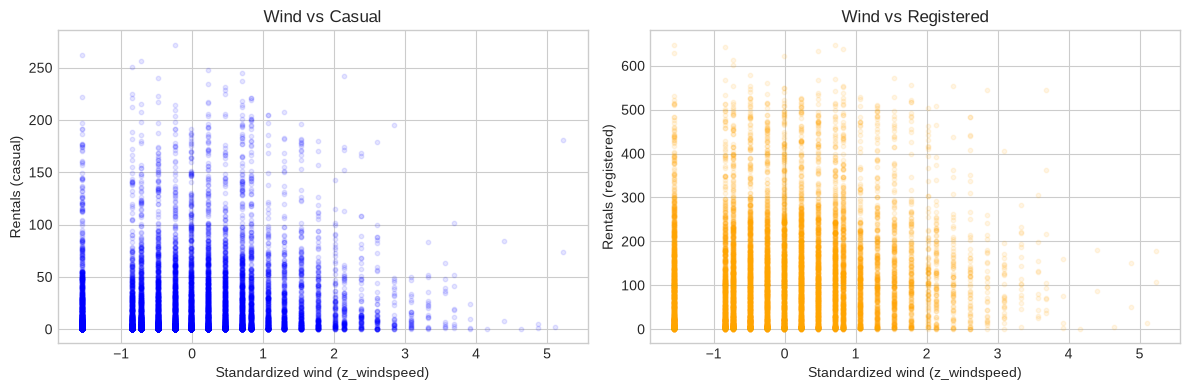

Simple wind coefficient (Casual): 2.7743823595067547
Full model wind coefficient (Casual): -1.6557311636548784
Casual     - Wind coefficient (b): -1.656, % of mean: -6.340%
Registered - Wind coefficient (b): -2.555, % of mean: -2.136%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X_train["z_windspeed"], train["casual"], alpha=0.1, s=10, color="blue")
axes[0].set_title("Wind vs Casual")
axes[0].set_xlabel("Standardized wind (z_windspeed)")
axes[0].set_ylabel("Rentals (casual)")

axes[1].scatter(X_train["z_windspeed"], train["registered"], alpha=0.1, s=10, color="orange")
axes[1].set_title("Wind vs Registered")
axes[1].set_xlabel("Standardized wind (z_windspeed)")
axes[1].set_ylabel("Rentals (registered)")

plt.tight_layout()
plt.show()

X_train_wind_only = X_train[["z_windspeed"]]

model_casual_simple = LinearRegression().fit(X_train_wind_only, train["casual"])
model_registered_simple = LinearRegression().fit(X_train_wind_only, train["registered"])

model_casual = LinearRegression()
model_casual.fit(X_train, train["casual"])

model_registered = LinearRegression()
model_registered.fit(X_train, train["registered"])

wind_index = X_train.columns.get_loc("z_windspeed")

print("Simple wind coefficient (Casual):", model_casual_simple.coef_[0])
print("Full model wind coefficient (Casual):", model_casual.coef_[wind_index])

b_casual = model_casual.coef_[wind_index]
b_registered = model_registered.coef_[wind_index]

pct_casual = 100 * b_casual / train["casual"].mean()
pct_registered = 100 * b_registered / train["registered"].mean()

print(f"Casual     - Wind coefficient (b): {b_casual:.3f}, % of mean: {pct_casual:.3f}%")
print(f"Registered - Wind coefficient (b): {b_registered:.3f}, % of mean: {pct_registered:.3f}%")

While high wind speed decreases ridership for both user groups, casual riders are significantly more sensitive to it, experiencing a demand drop equal to 6.34% of their mean compared to only a 2.14% relative drop for registered riders. Additionally, the casual wind coefficient flips from positive (2.77) in the simple model to negative (-1.66) in the full model, revealing that omitting confounding variables like temperature or time of day falsely masks the actual negative impact wind has on ridership.

**Weekend Weather Interactions**

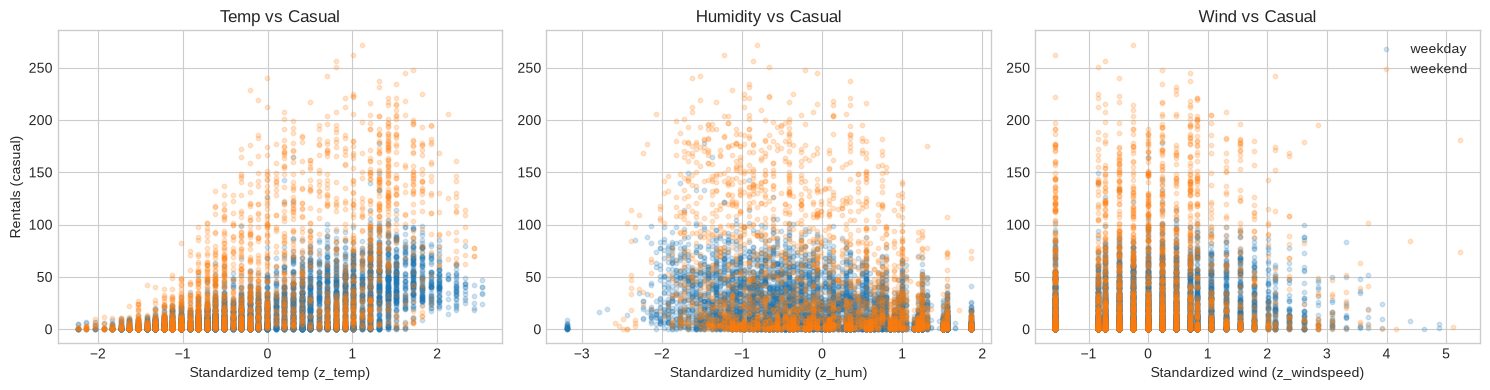

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for is_wknd, group_idx in train.groupby("is_weekend").groups.items():
    label = "weekend" if is_wknd else "weekday"
    axes[0].scatter(X_train.loc[group_idx, "z_temp"], train.loc[group_idx, "casual"], alpha=0.2, s=10, label=label)
axes[0].set_title("Temp vs Casual")
axes[0].set_xlabel("Standardized temp (z_temp)")
axes[0].set_ylabel("Rentals (casual)")

for is_wknd, group_idx in train.groupby("is_weekend").groups.items():
    label = "weekend" if is_wknd else "weekday"
    axes[1].scatter(X_train.loc[group_idx, "z_hum"], train.loc[group_idx, "casual"], alpha=0.2, s=10, label=label)
axes[1].set_title("Humidity vs Casual")
axes[1].set_xlabel("Standardized humidity (z_hum)")

for is_wknd, group_idx in train.groupby("is_weekend").groups.items():
    label = "weekend" if is_wknd else "weekday"
    axes[2].scatter(X_train.loc[group_idx, "z_windspeed"], train.loc[group_idx, "casual"], alpha=0.2, s=10, label=label)
axes[2].set_title("Wind vs Casual")
axes[2].set_xlabel("Standardized wind (z_windspeed)")
axes[2].legend()

plt.tight_layout()
plt.show()

Casual ridership is consistently higher on weekends than on weekdays across all weather conditions, reaching its absolute peak on warm weekends. While rising temperatures strongly stimulate weekend casual riding, adverse conditions like high humidity and strong winds uniformly suppress casual demand regardless of the day of the week.

**Baseline vs Interaction Models Fitting**

In [11]:
base_features = ["is_weekend", "z_temp", "z_hum", "z_windspeed", "hour_sin", "hour_cos"]
inter_features = base_features + ["wknd_x_temp", "wknd_x_hum", "wknd_x_wind"]

def fit_and_score(feature_names):
    model = LinearRegression().fit(X_train[feature_names], train["casual"])
    
    pred_train = model.predict(X_train[feature_names])
    pred_val = model.predict(X_valid[feature_names])
    
    scores = {
        "Train R2": r2_score(train["casual"], pred_train),
        "Train RMSE": np.sqrt(mean_squared_error(train["casual"], pred_train)),
        "Val R2": r2_score(val["casual"], pred_val),
        "Val RMSE": np.sqrt(mean_squared_error(val["casual"], pred_val)),
    }
    return model, pred_val, scores

baseline_model, baseline_prediction, baseline_scores = fit_and_score(base_features)
interaction_model, interaction_prediction, interaction_scores = fit_and_score(inter_features)

idx_temp = inter_features.index('wknd_x_temp')
idx_hum = inter_features.index('wknd_x_hum')
idx_wind = inter_features.index('wknd_x_wind')

print("Interaction Coefficients (Additional effect on weekends):")
print(f"Weekend x Temp: {interaction_model.coef_[idx_temp]:.3f}")
print(f"Weekend x Hum:  {interaction_model.coef_[idx_hum]:.3f}")
print(f"Weekend x Wind: {interaction_model.coef_[idx_wind]:.3f}\n")

pd.DataFrame(
    [baseline_scores, interaction_scores],
    index=["baseline", "with interaction"],
).round(3)

Interaction Coefficients (Additional effect on weekends):
Weekend x Temp: 18.597
Weekend x Hum:  -11.862
Weekend x Wind: -0.783



,Train R2,Train RMSE,Val R2,Val RMSE
baseline,0.552,24.541,0.381,50.114
with interaction,0.626,22.419,0.454,47.095


Adding weekend-weather interactions improves the model's predictive accuracy, increasing the validation $R^2$ score from 0.381 to 0.454 and lowering the validation RMSE from 50.114 to 47.095. The interaction coefficients indicate that casual riders are much more responsive to weather conditions on their days off; specifically, higher temperatures drive a significantly larger increase in weekend rentals (+18.597), while high humidity disproportionately suppresses weekend demand (-11.862).  

**Non-Linear Feature Addition (Temperature Squared)**

In [12]:
X_train["z_temp_sq"] = X_train["z_temp"] ** 2
X_valid["z_temp_sq"] = X_valid["z_temp"] ** 2
X_test["z_temp_sq"] = X_test["z_temp"] ** 2

nonlinear_features = base_features + ["z_temp_sq"]

nonlinear_model, _, nonlinear_scores = fit_and_score(nonlinear_features)

mean_casual = train["casual"].mean()
base_p_train = np.full(len(train), mean_casual)
base_p_val = np.full(len(val), mean_casual)

mean_baseline_scores = {
    "Train R2": r2_score(train["casual"], base_p_train),
    "Train RMSE": np.sqrt(mean_squared_error(train["casual"], base_p_train)),
    "Val R2": r2_score(val["casual"], base_p_val),
    "Val RMSE": np.sqrt(mean_squared_error(val["casual"], base_p_val)),
}

comparison_df = pd.DataFrame(
    [mean_baseline_scores, baseline_scores, nonlinear_scores, interaction_scores],
    index=["Training-Mean Baseline", "Linear (No Interactions)", "Non-Linear (Temp^2)", "Interaction Model"]
)

comparison_df.round(3)

,Train R2,Train RMSE,Val R2,Val RMSE
Training-Mean Baseline,0.000,36.661,-0.228,70.606
Linear (No Interactions),0.552,24.541,0.381,50.114
Non-Linear (Temp^2),0.552,24.541,0.382,50.108
Interaction Model,0.626,22.419,0.454,47.095


The comparison table reveals that the Interaction Model significantly outperforms the alternatives, achieving the highest validation $R^2$ (0.454) and the lowest validation RMSE (47.095). Furthermore, adding a non-linear temperature feature (Temp^2) provided almost no improvement over the standard linear model, suggesting that contextual behavioral factors—like how riders react differently to weather on weekends—are far more critical for predicting casual ridership than modeling complex weather curves. 

**Evaluating Registered Riders Models**

In [13]:
mean_reg = train["registered"].mean()
val_rmse_base_reg = np.sqrt(mean_squared_error(val["registered"], np.full(len(val), mean_reg)))

model_reg_linear = LinearRegression().fit(X_train[base_features], train["registered"])
val_rmse_lin_reg = np.sqrt(mean_squared_error(val["registered"], model_reg_linear.predict(X_valid[base_features])))

model_reg_inter = LinearRegression().fit(X_train[inter_features], train["registered"])
val_rmse_inter_reg = np.sqrt(mean_squared_error(val["registered"], model_reg_inter.predict(X_valid[inter_features])))

print(f"Registered Val RMSE - Baseline: {val_rmse_base_reg:.2f}")
print(f"Registered Val RMSE - Linear: {val_rmse_lin_reg:.2f}")
print(f"Registered Val RMSE - Interaction: {val_rmse_inter_reg:.2f}\n")

best_model_reg = model_reg_inter
best_features_reg = inter_features

Registered Val RMSE - Baseline: 198.22
Registered Val RMSE - Linear: 162.53
Registered Val RMSE - Interaction: 162.53



Unlike casual riders, incorporating weekend-weather interactions provides zero predictive improvement for registered riders, as both the linear and interaction models stall at identical validation RMSE scores of 162.53, implying that registered users are primarily routine commuters whose response to weather does not significantly shift just because it is the weekend.

**Final Evaluation on Test Data & Diagnostics**

CASUAL     | Baseline RMSE: 58.31 | Interaction Model RMSE: 39.19 (R2: 0.511)
REGISTERED | Baseline RMSE: 209.87 | Interaction Model RMSE: 180.27 (R2: 0.097)



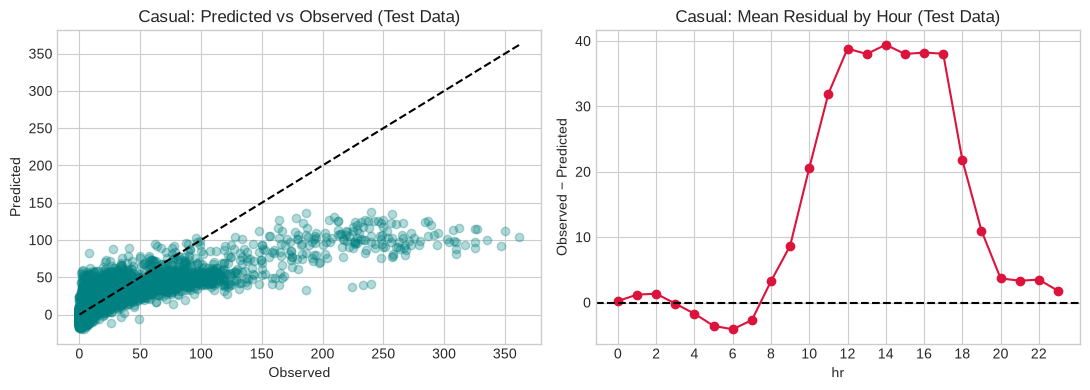

In [14]:
test_rmse_base_cas = np.sqrt(mean_squared_error(test["casual"], np.full(len(test), mean_casual)))
test_rmse_base_reg = np.sqrt(mean_squared_error(test["registered"], np.full(len(test), mean_reg)))

test_preds_cas = interaction_model.predict(X_test[inter_features])
test_rmse_cas = np.sqrt(mean_squared_error(test["casual"], test_preds_cas))
test_r2_cas = r2_score(test["casual"], test_preds_cas)

interaction_model_reg = model_reg_inter 
test_preds_reg = interaction_model_reg.predict(X_test[inter_features])
test_rmse_reg = np.sqrt(mean_squared_error(test["registered"], test_preds_reg))
test_r2_reg = r2_score(test["registered"], test_preds_reg)

print(f"CASUAL     | Baseline RMSE: {test_rmse_base_cas:.2f} | Interaction Model RMSE: {test_rmse_cas:.2f} (R2: {test_r2_cas:.3f})")
print(f"REGISTERED | Baseline RMSE: {test_rmse_base_reg:.2f} | Interaction Model RMSE: {test_rmse_reg:.2f} (R2: {test_r2_reg:.3f})\n")

diagnostic = test.copy()
diagnostic["prediction"] = test_preds_cas
diagnostic["residual"] = diagnostic["casual"] - diagnostic["prediction"] 

hour_diagnostic = diagnostic.groupby("hr").agg(
    mean_residual=("residual", "mean")
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(diagnostic["casual"], diagnostic["prediction"], alpha=0.3, color="teal")
limits = [0, max(diagnostic["casual"].max(), diagnostic["prediction"].max())]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set(title="Casual: Predicted vs Observed (Test Data)", xlabel="Observed", ylabel="Predicted")

hour_diagnostic["mean_residual"].plot(marker="o", ax=axes[1], color="crimson")
axes[1].axhline(0, color="black", linewidth=1.5, linestyle="--")
axes[1].set(title="Casual: Mean Residual by Hour (Test Data)", ylabel="Observed − Predicted")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

While the interaction model outperforms the baseline and explains roughly 51% of the variance in casual rentals ($R^2 = 0.511$), the diagnostic plots reveal a major systematic limitation: it severely underpredicts demand during mid-day hours (10:00 to 18:00), with predicted values flatlining far below the actual high-volume peaks.   

**Predict the Casual Share**

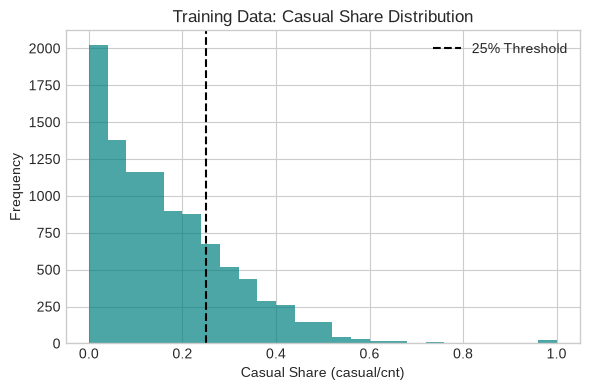

Validation R2: 0.262
Validation RMSE: 0.110
Predictions outside [0, 1]: 0


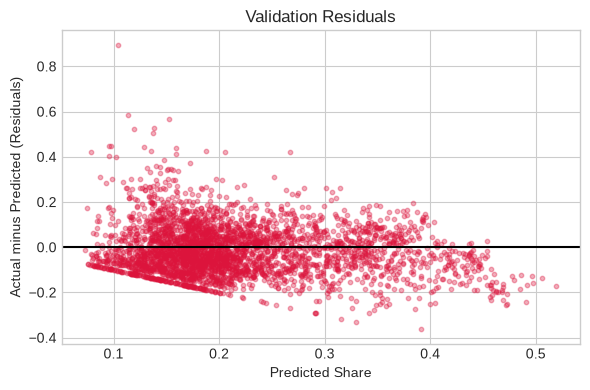

In [15]:
# Filter out rows where cnt == 0 and calculate share
train = train[train['cnt'] > 0].copy()
X_train = X_train.loc[train.index]
train['share'] = train['casual'] / train['cnt']

val = val[val['cnt'] > 0].copy()
X_valid = X_valid.loc[val.index]
val['share'] = val['casual'] / val['cnt']

test = test[test['cnt'] > 0].copy()
X_test = X_test.loc[test.index]
test['share'] = test['casual'] / test['cnt']

# Plot distribution of share in training data
fig, ax = plt.subplots(figsize=(6, 4))
train['share'].hist(bins=25, ax=ax, color='teal', alpha=0.7)
ax.axvline(0.25, color='black', linestyle='--', label='25% Threshold')
ax.set(xlabel='Casual Share (casual/cnt)', ylabel='Frequency', title='Training Data: Casual Share Distribution')
ax.legend()
plt.tight_layout()
plt.show()

# Fit Linear Regression
share_lr = LinearRegression().fit(X_train[inter_features], train['share'])
val_share_pred = share_lr.predict(X_valid[inter_features])

r2_share = r2_score(val['share'], val_share_pred)
rmse_share = np.sqrt(mean_squared_error(val['share'], val_share_pred))
out_of_bounds = ((val_share_pred < 0) | (val_share_pred > 1)).sum()

print(f"Validation R2: {r2_share:.3f}")
print(f"Validation RMSE: {rmse_share:.3f}")
print(f"Predictions outside [0, 1]: {out_of_bounds}")

# Plot residuals
residuals = val['share'] - val_share_pred
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(val_share_pred, residuals, s=10, alpha=0.35, color='crimson')
ax.axhline(0, color='black')
ax.set(xlabel='Predicted Share', ylabel='Actual minus Predicted (Residuals)', title='Validation Residuals')
plt.tight_layout()
plt.show()

The casual share distribution in the training data is heavily right-skewed, indicating that for the vast majority of hours, casual riders make up less than 25% of total rentals. The linear regression model attempting to predict this continuous share struggles with the non-normal distribution, evidenced by a low validation R2 of 0.262 and a residual plot showing heteroscedasticity, where prediction errors increase as the predicted share grows

**Predict a Class (Share > 25%)**

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
train['high_share'] = (train['share'] > 0.25).astype(int)
val['high_share'] = (val['share'] > 0.25).astype(int)
test['high_share'] = (test['share'] > 0.25).astype(int)

print("Training classes (0, 1):", train['high_share'].value_counts().sort_index().to_dict())
print("Validation classes (0, 1):", val['high_share'].value_counts().sort_index().to_dict(), "\n")

log_reg = LogisticRegression(max_iter=1000).fit(X_train[inter_features], train['high_share'])

val_probabilities = log_reg.predict_proba(X_valid[inter_features])[:, 1]
y_val_actual = val['high_share']
majority_class = train['high_share'].mode()[0]
baseline_preds = np.full(len(val), majority_class)

def score_classification(y_true, y_pred, name):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0)
    }

results = [score_classification(y_val_actual, baseline_preds, "Baseline (Majority Class)")]

for threshold in [0.50, 0.30]:
    preds = (val_probabilities >= threshold).astype(int)
    results.append(score_classification(y_val_actual, preds, f"Logistic (p >= {threshold})"))
    
    print(f"--- Confusion Matrix (Threshold {threshold}) ---")
    print(confusion_matrix(y_val_actual, preds, labels=[0, 1]))
    print()

display(pd.DataFrame(results).set_index("Model").round(3))

Training classes (0, 1): {0: 7740, 1: 2387}
Validation classes (0, 1): {0: 2209, 1: 1167} 

--- Confusion Matrix (Threshold 0.5) ---
[[1966  243]
 [ 563  604]]

--- Confusion Matrix (Threshold 0.3) ---
[[1666  543]
 [ 369  798]]



,Accuracy,Precision,Recall
Model,,,
Baseline (Majority Class),0.654,0.000,0.000
Logistic (p >= 0.5),0.761,0.713,0.518
Logistic (p >= 0.3),0.730,0.595,0.684


Because the dataset is imbalanced, a naive baseline model that always predicts the majority class achieves 65.4% accuracy without ever actually identifying a high-share hour. By using a logistic regression model and lowering the decision threshold from 0.5 to 0.3, the model becomes more aggressive at predicting high shares, which successfully catches more true positives (increasing recall from 51.8% to 68.4%) but makes more false-positive errors in the process, dropping precision from 71.3% to 59.5%.   


**Final Classification Evaluation on Test Data**

In [19]:
from sklearn.metrics import classification_report

# Choose 0.50 threshold based on validation accuracy
chosen_threshold = 0.50 

test_probabilities = log_reg.predict_proba(X_test[inter_features])[:, 1]
y_test_actual = test['high_share']

test_preds = (test_probabilities >= chosen_threshold).astype(int)

baseline_test_preds = np.full(len(test), majority_class)

test_results = [
    score_classification(y_test_actual, baseline_test_preds, "Baseline (Majority Class)"),
    score_classification(y_test_actual, test_preds, f"Logistic (p >= {chosen_threshold})")
]

print(f"--- Test Data Confusion Matrix (Threshold {chosen_threshold}) ---")
print(confusion_matrix(y_test_actual, test_preds, labels=[0, 1]))
print()

display(pd.DataFrame(test_results).set_index("Model").round(3))

print('BASELINE---------------------------------')
print(classification_report(y_test_actual, baseline_test_preds, zero_division=0))

print('LOGISTIC---------------------------------')
print(classification_report(y_test_actual, test_preds, zero_division=0))

--- Test Data Confusion Matrix (Threshold 0.5) ---
[[2526  199]
 [ 355  296]]



,Accuracy,Precision,Recall
Model,,,
Baseline (Majority Class),0.807,0.000,0.000
Logistic (p >= 0.5),0.836,0.598,0.455


BASELINE---------------------------------
              precision    recall  f1-score   support

           0       0.81      1.00      0.89      2725
           1       0.00      0.00      0.00       651

    accuracy                           0.81      3376
   macro avg       0.40      0.50      0.45      3376
weighted avg       0.65      0.81      0.72      3376

LOGISTIC---------------------------------
              precision    recall  f1-score   support

           0       0.88      0.93      0.90      2725
           1       0.60      0.45      0.52       651

    accuracy                           0.84      3376
   macro avg       0.74      0.69      0.71      3376
weighted avg       0.82      0.84      0.83      3376



The test data reveals a severe class imbalance where a baseline model achieves nearly 81% accuracy simply by never predicting a high casual share. Although the logistic model only slightly increases overall accuracy to 83.6%, it adds actual predictive value by successfully identifying 45.5% of the true high-share hours (recall) while maintaining a precision of roughly 60%.